In [1]:
from tensorflow import keras
from keras.models import Model
from keras import layers
from keras.layers import Dense, Input, BatchNormalization, Activation
from keras.layers import Conv2D, SeparableConv2D, MaxPooling2D, GlobalAveragePooling2D, GlobalMaxPooling2D
#from keras.applications.imagenet_utils import _obtain_input_shape
#from keras.utils.data_utils import get_file
from sklearn.model_selection import KFold
from keras.datasets import mnist
from PIL import Image
# for creating a one hot vector for labels
#from keras.utils import np_utils
from IPython.display import display, Image
#import the models
from keras import Model
#add layers
from keras import layers
#add optimizer
from keras import optimizers
#add loss function 
from keras import losses
import random

import keras
import numpy as np
import pandas as pd 
import os
import seaborn as sns
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import tensorflow as tf
import tensorflow.keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, Flatten, Dropout, MaxPooling2D
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2
import json
from skimage.metrics import structural_similarity as ssim

print("Hello world.")

Hello world.


In [2]:
def create_mask_from_json(json_file, height, width):

    # If file does not exist or is empty
    if not os.path.exists(json_file) or os.path.getsize(json_file) == 0:
        return np.zeros((height, width), dtype=np.uint8)

    with open(json_file, "r") as f:
        try:
            data = json.load(f)
        except json.JSONDecodeError:
            return np.zeros((height, width), dtype=np.uint8)

    mask = np.zeros((height, width), dtype=np.uint8)

    for shape in data.get("shapes", []):
        pts = np.array(shape["points"], dtype=np.int32)
        pts = pts.reshape((-1, 1, 2))
        cv2.fillPoly(mask, [pts], 255)

    return mask

In [3]:
def apply_perturbations(images, perturbation):
   

    perturbed_images = []
    p_type = perturbation.get("type")

    for img in images:
        img_copy = img.copy()

        # ---------------- GAUSSIAN BLUR ----------------
        if p_type == 'gaussian_blur':
            k = perturbation.get('kernel_size', 5)
            if k % 2 == 0:
                k += 1
            img_copy = cv2.GaussianBlur(img_copy, (k, k), 0)

        # ---------------- NOISE ----------------
        elif p_type == 'noise':
            mean = perturbation.get('mean', 0)
            std = perturbation.get('std', 0.05)
            noise = np.random.normal(mean, std, img_copy.shape)
            img_copy = np.clip(img_copy + noise, 0, 1)

        # ---------------- BRIGHTNESS ----------------
        elif p_type == 'brightness':
            factor = perturbation.get('factor', 0.2)
            img_copy = np.clip(img_copy + factor, 0, 1)

        # ---------------- HUE SHIFT ----------------
        elif p_type == 'hue_shift':
            hsv = cv2.cvtColor((img_copy * 255).astype(np.uint8), cv2.COLOR_RGB2HSV)
            hsv[..., 0] = (hsv[..., 0] + perturbation.get('shift', 10)) % 180
            img_copy = cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB).astype(np.float32) / 255.0

        # ---------------- CONTRAST ----------------
        elif p_type == 'contrast':
            factor = perturbation.get('factor', 1.0)
            mean = np.mean(img_copy, axis=(0, 1), keepdims=True)
            img_copy = np.clip((img_copy - mean) * factor + mean, 0, 1)

        # ---------------- GAMMA ----------------
        elif p_type == 'gamma':
            gamma = max(perturbation.get('gamma', 1.0), 1e-6)
            img_copy = np.clip(img_copy ** gamma, 0, 1)

        # ---------------- MOTION BLUR ----------------
        elif p_type == 'motion_blur':
            k = perturbation.get('kernel_size', 7)
            if k % 2 == 0:
                k += 1

            kernel = np.zeros((k, k))
            kernel[k // 2, :] = np.ones(k)
            kernel = kernel / k

            img_copy = cv2.filter2D(img_copy, -1, kernel)

        # ---------------- COMPRESSION ----------------
        elif p_type == 'compression':
            quality = perturbation.get('quality', 30)

            encode_param = [int(cv2.IMWRITE_JPEG_QUALITY), quality]
            img_uint8 = (img_copy * 255).astype(np.uint8)

            _, encimg = cv2.imencode('.jpg', img_uint8, encode_param)
            decimg = cv2.imdecode(encimg, 1)

            img_copy = decimg.astype(np.float32) / 255.0

        # ---------------- OCCLUSION ----------------
        elif p_type == 'occlusion':
            size = perturbation.get('size', 0.2)
            h, w = img_copy.shape[:2]

            occ_h = int(h * size)
            occ_w = int(w * size)

            y = np.random.randint(0, h - occ_h)
            x = np.random.randint(0, w - occ_w)

            img_copy[y:y+occ_h, x:x+occ_w] = 0.0

        # ---------------- ERROR HANDLING ----------------
        else:
            raise ValueError(f"Unsupported perturbation type: {p_type}")

        perturbed_images.append(img_copy)

    return np.array(perturbed_images, dtype=np.float32)

In [4]:
x = []
label = []
x_validation = []
label_validation = []
x_test = []
image_test= []
label_test = []
mask_test = []
img_size = 224

original_test_images = []

In [5]:

image_folder0 = "/kaggle/input/datasets/ragibmehedi/flower-dataset-tensorflow/flower_photos/flower_photos/flower_photos/daisy"
csv_file0 = pd.read_csv("/kaggle/input/datasets/ragibmehedi/flower-dataset-tensorflow/split_files/daisy_split.csv")
json_folder = "/kaggle/input/datasets/ragibmehedi/flower-dataset-tensorflow/json_files/daisy"


columns = csv_file0.columns
print(list(columns))

for i in range(0, len(csv_file0)):
    image_name = csv_file0.loc[i]["image"]
    fold = csv_file0.loc[i]["used_for"]
    
    image = cv2.imread(image_folder0 +'/'+ image_name)
    image_original = image
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0


    if fold == "testing":
        original_test_images.append(image_original)
        x_test.append(image)
        label_test.append([0])
        json_name = image_name.replace(".jpg", ".json")
        print(image_name," ", json_name)
        json_file = json_folder + '/' +json_name
        mask = create_mask_from_json( json_file , image_original.shape[0], image_original.shape[1])
        mask = cv2.resize(mask, (img_size, img_size))
        mask_test.append(mask)
    elif fold == "validation":
        x_validation.append(image)
        label_validation.append([0])
    else:
        x.append(image)
        label.append([0])



print(len(x)," ", len(label))
print(len(x_validation)," ",len(label_validation))
print(len(x_test)," ",len(label_test))
print("Hello world.")

['Unnamed: 0', 'image', 'used_for']
5765646947_82e95a9cc9_n.jpg   5765646947_82e95a9cc9_n.json
9242705328_eee8402a8d.jpg   9242705328_eee8402a8d.json
1031799732_e7f4008c03.jpg   1031799732_e7f4008c03.json
3628485766_4ff937954a_n.jpg   3628485766_4ff937954a_n.json
5135131051_102d4878ca_n.jpg   5135131051_102d4878ca_n.json
21805938544_bf6bb0e4bc.jpg   21805938544_bf6bb0e4bc.json
4141147800_813f660b47.jpg   4141147800_813f660b47.json
2862944799_45bc8e7302.jpg   2862944799_45bc8e7302.json
8719756744_34a5a83976_n.jpg   8719756744_34a5a83976_n.json
10712722853_5632165b04.jpg   10712722853_5632165b04.json
16401288243_36112bd52f_m.jpg   16401288243_36112bd52f_m.json
2521408074_e6f86daf21_n.jpg   2521408074_e6f86daf21_n.json
3336704121_cfeb67a7d7.jpg   3336704121_cfeb67a7d7.json
3080880039_4f1bd592e5_n.jpg   3080880039_4f1bd592e5_n.json
4333085242_bbeb3e2841_m.jpg   4333085242_bbeb3e2841_m.json
16360180712_b72695928c_n.jpg   16360180712_b72695928c_n.json
7410356270_9dff4d0e2e_n.jpg   7410356270

In [6]:


image_folder1 = "/kaggle/input/datasets/ragibmehedi/flower-dataset-tensorflow/flower_photos/flower_photos/flower_photos/dandelion"
csv_file1 = pd.read_csv("/kaggle/input/datasets/ragibmehedi/flower-dataset-tensorflow/split_files/dandelion_split.csv")
json_folder = "/kaggle/input/datasets/ragibmehedi/flower-dataset-tensorflow/json_files/Dandelion"


columns = csv_file1.columns
print(list(columns))

for i in range(0, len(csv_file1)):
    image_name = csv_file1.loc[i]["image"]
    fold = csv_file1.loc[i]["used_for"]
    
    image = cv2.imread(image_folder1 +'/'+ image_name)
    image_original = image
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0


    if fold == "testing":
        original_test_images.append(image_original)
        x_test.append(image)
        label_test.append([1])
        json_name = image_name.replace(".jpg", ".json")
        print(image_name," ", json_name)
        json_file = json_folder + '/' +json_name
        mask = create_mask_from_json( json_file , image_original.shape[0], image_original.shape[1])
        mask = cv2.resize(mask, (img_size, img_size))
        mask_test.append(mask)
    elif fold == "validation":
        x_validation.append(image)
        label_validation.append([1])
    else:
        x.append(image)
        label.append([1])


print(len(x)," ", len(label))
print(len(x_validation)," ",len(label_validation))
print(len(x_test)," ",len(label_test))
print("Hello world.")

['Unnamed: 0', 'image', 'used_for']
4512569988_2b3f802cc6.jpg   4512569988_2b3f802cc6.json
7232035352_84a39e99ba_n.jpg   7232035352_84a39e99ba_n.json
3533075436_0954145b9f_m.jpg   3533075436_0954145b9f_m.json
4844697927_c70d644f40_n.jpg   4844697927_c70d644f40_n.json
4607183665_3472643bc8.jpg   4607183665_3472643bc8.json
8689302980_9bd2f7b9fe_n.jpg   8689302980_9bd2f7b9fe_n.json
3581252194_8c976d333a_n.jpg   3581252194_8c976d333a_n.json
3419172904_7708414ae9_n.jpg   3419172904_7708414ae9_n.json
4634716478_1cbcbee7ca.jpg   4634716478_1cbcbee7ca.json
15358221063_2c6e548e84.jpg   15358221063_2c6e548e84.json
4645101643_9c9d9df13e.jpg   4645101643_9c9d9df13e.json
8647874151_aac8db2588_m.jpg   8647874151_aac8db2588_m.json
3591588855_b4fd53b000.jpg   3591588855_b4fd53b000.json
2465573725_d78caca9d4_n.jpg   2465573725_d78caca9d4_n.json
3419166382_a5e4b8fe6d_m.jpg   3419166382_a5e4b8fe6d_m.json
19437578578_6ab1b3c984.jpg   19437578578_6ab1b3c984.json
3856725141_0db85f466d_n.jpg   3856725141_0db

In [7]:

image_folder2 = "/kaggle/input/datasets/ragibmehedi/flower-dataset-tensorflow/flower_photos/flower_photos/flower_photos/roses"
csv_file2 = pd.read_csv("/kaggle/input/datasets/ragibmehedi/flower-dataset-tensorflow/split_files/roses_split.csv")
json_folder = "/kaggle/input/datasets/ragibmehedi/flower-dataset-tensorflow/json_files/roses"


columns = csv_file2.columns
print(list(columns))

for i in range(0, len(csv_file2)):
    image_name = csv_file2.loc[i]["image"]
    fold = csv_file2.loc[i]["used_for"]
    
    image = cv2.imread(image_folder2 +'/'+ image_name)
    image_original = image
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0


    if fold == "testing":
        x_test.append(image)
        label_test.append([2])
        original_test_images.append(image_original)
        json_name = image_name.replace(".jpg", ".json")
        print(image_name," ", json_name)
        json_file = json_folder + '/' +json_name
        mask = create_mask_from_json( json_file , image_original.shape[0], image_original.shape[1])
        mask = cv2.resize(mask, (img_size, img_size))
        mask_test.append(mask)
    elif fold == "validation":
        x_validation.append(image)
        label_validation.append([2])
    else:
        x.append(image)
        label.append([2])


print(len(x)," ", len(label))
print(len(x_validation)," ",len(label_validation))
print(len(x_test)," ",len(label_test))
print("Hello world.")

['Unnamed: 0', 'image', 'used_for']
8125886145_ae99f91fd0.jpg   8125886145_ae99f91fd0.json
1788484468_f73afa6c32_n.jpg   1788484468_f73afa6c32_n.json
19440805164_920b28da61_n.jpg   19440805164_920b28da61_n.json
3208417632_19138d8e35_n.jpg   3208417632_19138d8e35_n.json
20825078671_90b0389c70_m.jpg   20825078671_90b0389c70_m.json
8775267816_726ddc6d92_n.jpg   8775267816_726ddc6d92_n.json
12240165555_98625b1e88_n.jpg   12240165555_98625b1e88_n.json
4325834819_ab56661dcc_m.jpg   4325834819_ab56661dcc_m.json
2863863372_605e29c03e_m.jpg   2863863372_605e29c03e_m.json
7455236056_b6d71a8dab.jpg   7455236056_b6d71a8dab.json
11944957684_2cc806276e.jpg   11944957684_2cc806276e.json
13231224664_4af5293a37.jpg   13231224664_4af5293a37.json
2065522422_cfdd80044a_n.jpg   2065522422_cfdd80044a_n.json
17449165090_dfb27af360_n.jpg   17449165090_dfb27af360_n.json
6676529655_9672b6f955_m.jpg   6676529655_9672b6f955_m.json
2976723295_b16ab04231.jpg   2976723295_b16ab04231.json
3315973481_850d2253e9_n.jpg 

In [8]:

image_folder3 = "/kaggle/input/datasets/ragibmehedi/flower-dataset-tensorflow/flower_photos/flower_photos/flower_photos/sunflowers"
csv_file3 = pd.read_csv("/kaggle/input/datasets/ragibmehedi/flower-dataset-tensorflow/split_files/sunflowers_split.csv")
json_folder = "/kaggle/input/datasets/ragibmehedi/flower-dataset-tensorflow/json_files/sunflowers"


columns = csv_file3.columns
print(list(columns))

for i in range(0, len(csv_file3)):
    image_name = csv_file3.loc[i]["image"]
    fold = csv_file3.loc[i]["used_for"]
    
    image = cv2.imread(image_folder3 +'/'+ image_name)
    image_original = image
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0


    if fold == "testing":
        x_test.append(image)
        label_test.append([3])
        original_test_images.append(image_original)
        json_name = image_name.replace(".jpg", ".json")
        print(image_name," ", json_name)
        json_file = json_folder + '/' +json_name
        mask = create_mask_from_json( json_file , image_original.shape[0], image_original.shape[1])
        mask = cv2.resize(mask, (img_size, img_size))
        mask_test.append(mask)
    elif fold == "validation":
        x_validation.append(image)
        label_validation.append([3])
    else:
        x.append(image)
        label.append([3])


print(len(x)," ", len(label))
print(len(x_validation)," ",len(label_validation))
print(len(x_test)," ",len(label_test))
print("Hello world.")

['Unnamed: 0', 'image', 'used_for']
7586498522_4dcab1c8d2_m.jpg   7586498522_4dcab1c8d2_m.json
5067864967_19928ca94c_m.jpg   5067864967_19928ca94c_m.json
5020805619_6c710793f7.jpg   5020805619_6c710793f7.json
3897174387_07aac6bf5f_n.jpg   3897174387_07aac6bf5f_n.json
20972862281_5367f4af88.jpg   20972862281_5367f4af88.json
6606817351_10f6e43a09.jpg   6606817351_10f6e43a09.json
287233531_74d4605814_m.jpg   287233531_74d4605814_m.json
4868595281_1e58083785.jpg   4868595281_1e58083785.json
20344282483_05abb0b837.jpg   20344282483_05abb0b837.json
265422922_bbbde781d2_m.jpg   265422922_bbbde781d2_m.json
23356825566_f5885875f2.jpg   23356825566_f5885875f2.json
14928117202_139d2142cc_n.jpg   14928117202_139d2142cc_n.json
15973657966_d6f6005539_n.jpg   15973657966_d6f6005539_n.json
15493195788_60530f2398_m.jpg   15493195788_60530f2398_m.json
20156280765_a6baea3176.jpg   20156280765_a6baea3176.json
2816503473_580306e772.jpg   2816503473_580306e772.json
6265084065_7a8b30cc6e_n.jpg   6265084065_7

In [9]:

image_folder4 = "/kaggle/input/datasets/ragibmehedi/flower-dataset-tensorflow/flower_photos/flower_photos/flower_photos/tulips"
csv_file4 = pd.read_csv("/kaggle/input/datasets/ragibmehedi/flower-dataset-tensorflow/split_files/tulips_split.csv")
json_folder = "/kaggle/input/datasets/ragibmehedi/flower-dataset-tensorflow/json_files/tulips"


columns = csv_file4.columns
print(list(columns))

for i in range(0, len(csv_file4)):
    image_name = csv_file4.loc[i]["image"]
    fold = csv_file4.loc[i]["used_for"]
    
    image = cv2.imread(image_folder4 +'/'+ image_name)
    image_original = image
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0


    if fold == "testing":
        x_test.append(image)
        label_test.append([4])
        original_test_images.append(image_original)
        json_name = image_name.replace(".jpg", ".json")
        print(image_name," ", json_name)
        json_file = json_folder + '/' +json_name
        mask = create_mask_from_json( json_file , image_original.shape[0], image_original.shape[1])
        mask = cv2.resize(mask, (img_size, img_size))
        mask_test.append(mask)
    elif fold == "validation":
        x_validation.append(image)
        label_validation.append([4])
    else:
        x.append(image)
        label.append([4])


print(len(x)," ", len(label))
print(len(x_validation)," ",len(label_validation))
print(len(x_test)," ",len(label_test))
print("Hello world.")

['Unnamed: 0', 'image', 'used_for']
510698601_9f61d6f8d8.jpg   510698601_9f61d6f8d8.json
6936168062_a31c28b77c_m.jpg   6936168062_a31c28b77c_m.json
142235017_07816937c6.jpg   142235017_07816937c6.json
14124669683_7fb74f20c3.jpg   14124669683_7fb74f20c3.json
14066056226_d8564a083e_m.jpg   14066056226_d8564a083e_m.json
13900235284_32ce563633_n.jpg   13900235284_32ce563633_n.json
8762193202_0fbf2f6a81.jpg   8762193202_0fbf2f6a81.json
13910131718_731353d84c_n.jpg   13910131718_731353d84c_n.json
113291410_1bdc718ed8_n.jpg   113291410_1bdc718ed8_n.json
137126311_debe64c6a8_n.jpg   137126311_debe64c6a8_n.json
495094547_fd2d999c44.jpg   495094547_fd2d999c44.json
15029962436_3e50c1f30f_n.jpg   15029962436_3e50c1f30f_n.json
8768645961_8f1e097170_n.jpg   8768645961_8f1e097170_n.json
164578909_51f245d3fa_n.jpg   164578909_51f245d3fa_n.json
4522764992_e9d70b82c1_m.jpg   4522764992_e9d70b82c1_m.json
4588904196_3c5825c7f4.jpg   4588904196_3c5825c7f4.json
9947374414_fdf1d0861c_n.jpg   9947374414_fdf1d

In [10]:
x = np.asarray(x)
x_validation = np.asarray(x_validation)
x_test = np.asarray(x_test)

print(len(x)," ", len(x_validation)," ", len(x_test))

2935   368   367


In [11]:
from tensorflow.keras.utils import to_categorical 

label = np.array(label)
label = to_categorical(label , 5 )
print(len(label))



label_validation = np.array(label_validation)
label_validation = to_categorical(label_validation , 5 )
print(len(label_validation))

label_test = np.array(label_test)
label_test = to_categorical(label_test , 5 )
print(len(label_test))

2935
368
367


In [12]:
x_test_blur = apply_perturbations(x_test, {'type':'gaussian_blur','kernel_size':5})
x_test_noise = apply_perturbations(x_test, {'type':'noise','mean':0,'std':0.05})
x_test_brightness = apply_perturbations(x_test, {'type':'brightness','factor':0.2})
x_test_hue = apply_perturbations(x_test, {'type':'hue_shift','shift':15})
x_test_contrast = apply_perturbations(
    x_test,
    {'type': 'contrast', 'factor': 0.5}
)

x_test_gamma = apply_perturbations(
    x_test,
    {'type': 'gamma', 'gamma': 2.0}
)

x_test_motion_blur = apply_perturbations(
    x_test,
    {'type': 'motion_blur', 'kernel_size': 7}
)
# ---------------- COMPRESSION ----------------
x_test_compression = apply_perturbations(
    x_test,
    {'type': 'compression', 'quality': 30}   # lower = stronger compression
)

# ---------------- OCCLUSION ----------------
x_test_occlusion = apply_perturbations(
    x_test,
    {'type': 'occlusion', 'size': 0.2}   # 20% area blocked
)



x_test_blur = np.array(x_test_blur, dtype=np.float32)
x_test_noise = np.array(x_test_noise, dtype=np.float32)
x_test_brightness = np.array(x_test_brightness, dtype=np.float32)
x_test_hue = np.array(x_test_hue, dtype=np.float32)
x_test_contrast = np.array(x_test_contrast , dtype=np.float32)
x_test_gamma = np.array(x_test_gamma , dtype=np.float32)
x_test_motion_blur = np.array(x_test_motion_blur , dtype=np.float32)
x_test_compression = np.array(x_test_compression , dtype=np.float32)
x_test_occlusion = np.array(x_test_occlusion , dtype=np.float32)

print("Hello world.")

Hello world.


In [13]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Dense


model_path = "/kaggle/input/datasets/ragibmehedi/flower-dataset-tensorflow/keras_files/keras_files/Custom_CNN_tf_flowers.keras"

model = keras.models.load_model(model_path) 

model.summary()

I0000 00:00:1785581403.672402      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1785581403.675149      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36864)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     9,437,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,481,425 (112.46 MB)

 Trainable params: 9,827,141 (37.49 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 19,654,284 (74.98 MB)

In [14]:
test_loss, test_accuracy = model.evaluate(x_test, label_test )
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Loss: {test_loss:.4f}")

10/12 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.7212 - loss: 1.3003

I0000 00:00:1785581409.775968     130 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 113ms/step - accuracy: 0.7003 - loss: 1.4483
Test Accuracy: 0.7003
Test Loss: 1.4483


In [15]:
test_loss_noise , test_accuracy_noise = model.evaluate(x_test_noise, label_test)
print(f"Test Accuracy noise: {test_accuracy_noise:.4f}")
print(f"Test Loss noise: {test_loss_noise:.4f}")

test_loss_blur , test_accuracy_blur = model.evaluate(x_test_blur, label_test)
print(f"Test Accuracy blur: {test_accuracy_blur:.4f}")
print(f"Test Loss blur: {test_loss_blur:.4f}")


test_loss_brightness , test_accuracy_brightness = model.evaluate(x_test_brightness, label_test)
print(f"Test Accuracy brightness: {test_accuracy_brightness:.4f}")
print(f"Test Loss brightness: {test_loss_brightness:.4f}")

test_loss_hue , test_accuracy_hue = model.evaluate(x_test_hue , label_test)
print(f"Test Accuracy hue: {test_accuracy_hue:.4f}")
print(f"Test Loss hue: {test_loss_hue:.4f}")

test_loss_contrast, test_accuracy_contrast = model.evaluate(x_test_contrast, label_test )
print(f"Test Accuracy contrast: {test_accuracy_contrast:.4f}")
print(f"Test Loss contrast: {test_loss_contrast:.4f}")

test_loss_gamma, test_accuracy_gamma = model.evaluate(x_test_gamma , label_test )
print(f"Test Accuracy gamma: {test_accuracy_gamma:.4f}")
print(f"Test Loss gamma: {test_loss_gamma:.4f}")

test_loss_motion_blur , test_accuracy_motion_blur = model.evaluate(x_test_motion_blur , label_test )
print(f"Test Accuracy blur: {test_accuracy_motion_blur:.4f}")
print(f"Test Loss blur: {test_loss_motion_blur:.4f}")

test_loss_compression, test_accuracy_compression = model.evaluate(x_test_compression, label_test )
print(f"Test Accuracy compression: {test_accuracy_compression:.4f}")
print(f"Test Loss compression: {test_loss_compression:.4f}")

test_loss_occlusion, test_accuracy_occlusion = model.evaluate(x_test_occlusion, label_test )
print(f"Test Accuracy occlusion: {test_accuracy_occlusion:.4f}")
print(f"Test Loss occlusion: {test_loss_occlusion:.4f}")

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6866 - loss: 1.4744
Test Accuracy noise: 0.6866
Test Loss noise: 1.4744
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6785 - loss: 1.6642
Test Accuracy blur: 0.6785
Test Loss blur: 1.6642
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6403 - loss: 1.8599
Test Accuracy brightness: 0.6403
Test Loss brightness: 1.8599
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.5559 - loss: 3.1910
Test Accuracy hue: 0.5559
Test Loss hue: 3.1910
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.5204 - loss: 2.2771
Test Accuracy contrast: 0.5204
Test Loss contrast: 2.2771
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6403 - loss: 1.7172
Test Accuracy gamma: 0.6403
Test Loss gamma: 1.7172
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6649 - loss: 1.6770
Test Accuracy blur: 0.6649
Test Loss blur: 1.6770
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6948 - loss: 1.5161
Test Accuracy compression: 0.6948
Te

In [16]:
accuracy_stability_noise = 1 - (abs(test_accuracy - test_accuracy_noise))/ (test_accuracy + test_accuracy_noise + 1e-8)
print(f"accuracy_stability_noise : {accuracy_stability_noise }")

accuracy_stability_blur = 1 - (abs(test_accuracy - test_accuracy_blur))/ (test_accuracy + test_accuracy_blur + 1e-8)
print(f"accuracy_stability_blur : {accuracy_stability_blur }")

accuracy_stability_brightness = 1 - (abs(test_accuracy - test_accuracy_brightness))/ (test_accuracy + test_accuracy_brightness + 1e-8)
print(f"accuracy_stability_brightness : {accuracy_stability_brightness }")

accuracy_stability_hue = 1 - (abs(test_accuracy - test_accuracy_hue))/ (test_accuracy + test_accuracy_hue + 1e-8)
print(f"accuracy_stability_hue : {accuracy_stability_hue }")

accuracy_stability_contrast = 1 - (abs(test_accuracy - test_accuracy_contrast))/ (test_accuracy + test_accuracy_contrast + 1e-8)
print(f"accuracy_stability_contrast : {accuracy_stability_contrast }")

accuracy_stability_gamma = 1 - (abs(test_accuracy - test_accuracy_gamma))/ (test_accuracy + test_accuracy_gamma + 1e-8)
print(f"accuracy_stability_gamma : {accuracy_stability_gamma }")

accuracy_stability_motion_blur = 1 - (abs(test_accuracy - test_accuracy_motion_blur))/ (test_accuracy + test_accuracy_motion_blur + 1e-8)
print(f"accuracy_stability_motion_blur : {accuracy_stability_motion_blur }")

accuracy_stability_compression = 1 - (abs(test_accuracy - test_accuracy_compression))/ (test_accuracy + test_accuracy_compression + 1e-8)
print(f"accuracy_stability_compression : {accuracy_stability_compression }")

accuracy_stability_occlusion = 1 - (abs(test_accuracy - test_accuracy_occlusion))/ (test_accuracy + test_accuracy_occlusion + 1e-8)
print(f"accuracy_stability_occlusion : {accuracy_stability_occlusion }")

accuracy_stability_noise : 0.9901767927052849
accuracy_stability_blur : 0.9841897186503671
accuracy_stability_brightness : 0.9552845392623636
accuracy_stability_hue : 0.8850325271421221
accuracy_stability_contrast : 0.8526785783029485
accuracy_stability_gamma : 0.9552845392623636
accuracy_stability_motion_blur : 0.9740518660692318
accuracy_stability_compression : 0.996093748859754
accuracy_stability_occlusion : 0.9821781905031295


In [17]:
for layer in model.layers:
    print( layer.name, layer.output.shape)

input_layer (None, 224, 224, 3)
conv2d (None, 222, 222, 32)
max_pooling2d (None, 111, 111, 32)
conv2d_1 (None, 109, 109, 64)
max_pooling2d_1 (None, 54, 54, 64)
conv2d_2 (None, 52, 52, 128)
max_pooling2d_2 (None, 26, 26, 128)
conv2d_3 (None, 24, 24, 256)
max_pooling2d_3 (None, 12, 12, 256)
flatten (None, 36864)
dense (None, 256)
dropout (None, 256)
dense_1 (None, 5)


In [18]:
last_conv_layer_name = None

for layer in reversed(model.layers):
    if 'conv' in layer.name.lower():
        last_conv_layer_name = layer.name
        break

print(f"Last convolutional layer: {last_conv_layer_name}")

Last convolutional layer: conv2d_3


In [19]:
# ----------------------------
# Grad-CAM heatmap function
# ----------------------------
def get_gradcam_heatmap(model, img_array, last_conv_layer_name, pred_index=None):
    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array, training=False)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]  # (H, W, C)
    heatmap = tf.reduce_sum(conv_outputs * pooled_grads, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), predictions.numpy()[0], int(pred_index)


def binarize_heatmap(heatmap, target_shape, threshold=0.5):
    heatmap_resized = cv2.resize(heatmap, (target_shape[1], target_shape[0]))
    return (heatmap_resized > threshold).astype(np.uint8)

def binarize_mask(mask):
    return (mask > 0).astype(np.uint8)

def LMOS(pred_bin, mask_bin):
    intersection = np.logical_and(pred_bin, mask_bin).sum()
    pred_area = pred_bin.sum()
    return (intersection / pred_area)  if pred_area != 0 else 0.0


overlap_pred_array = []
overlap_pred_noise_array = []
overlap_pred_blur_array = []
overlap_pred_brightness_array = []
overlap_pred_hue_array = []
overlap_pred_contrast_array = []
overlap_pred_gamma_array = []
overlap_pred_motion_blur_array = []
overlap_pred_compression_array = []
overlap_pred_occlusion_array = []

drop_noise = []
drop_blur = []
drop_brightness = []
drop_hue = []
drop_contrast = []
drop_gamma = []
drop_motion_blur = []
drop_compression = []
drop_occlusion = []


for idx in range(len(x_test)):
    # Prepare image for model
    print("idx ", idx)
    img_array = x_test[idx]
    img_array_noise = x_test_noise[idx]
    img_array_brightness = x_test_brightness[idx]
    img_array_blur = x_test_blur[idx]
    img_array_hue = x_test_hue[idx]
    img_array_contrast = x_test_contrast[idx]
    img_array_gamma = x_test_gamma[idx]
    img_array_motion_blur = x_test_motion_blur[idx]
    img_array_compression = x_test_compression[idx]
    img_array_occlusion = x_test_occlusion[idx]
    
    if len(img_array.shape) == 3:
        img_array_exp = np.expand_dims(img_array, axis=0)
        img_array_noise_exp = np.expand_dims(img_array_noise , axis=0)
        img_array_brightness_exp = np.expand_dims(img_array_brightness, axis=0)
        img_array_blur_exp = np.expand_dims(img_array_blur, axis=0)
        img_array_hue_exp = np.expand_dims(img_array_hue, axis=0)
        img_array_contrast_exp = np.expand_dims(img_array_contrast , axis=0)
        img_array_gamma_exp = np.expand_dims(img_array_gamma , axis=0)
        img_array_motion_blur_exp = np.expand_dims(img_array_motion_blur, axis=0)
        img_array_compression_exp = np.expand_dims(img_array_compression , axis=0)
        img_array_occlusion_exp = np.expand_dims(img_array_occlusion, axis=0)

    # True label
    true_label = int(label_test[idx]) if len(np.array(label_test[idx]).shape) == 0 else int(np.argmax(label_test[idx]))

    # Grad-CAM
    heatmap_pred, pred_probs, pred_label = get_gradcam_heatmap(model, img_array_exp, last_conv_layer_name)
    heatmap_pred_noise, pred_probs_noise, pred_label_noise = get_gradcam_heatmap(model, img_array_noise_exp, last_conv_layer_name)
    heatmap_pred_brightness, pred_probs_brightness, pred_label_brightness = get_gradcam_heatmap(model, img_array_brightness_exp, last_conv_layer_name)
    heatmap_pred_blur, pred_probs_blur, pred_label_blur = get_gradcam_heatmap(model, img_array_blur_exp, last_conv_layer_name)
    heatmap_pred_hue, pred_probs_hue, pred_label_hue = get_gradcam_heatmap(model, img_array_hue_exp, last_conv_layer_name)
    heatmap_pred_contrast, pred_probs_contrast, pred_label_contrast = get_gradcam_heatmap(model, img_array_contrast_exp, last_conv_layer_name)
    heatmap_pred_gamma, pred_probs_gamma, pred_label_gamma = get_gradcam_heatmap(model, img_array_gamma_exp, last_conv_layer_name)
    heatmap_pred_motion_blur, pred_probs_motion_blur, pred_label_motion_blur = get_gradcam_heatmap(model, img_array_motion_blur_exp, last_conv_layer_name)
    heatmap_pred_compression, pred_probs_compression, pred_label_compression = get_gradcam_heatmap(model, img_array_compression_exp, last_conv_layer_name)
    heatmap_pred_occlusion, pred_probs_occlusion, pred_label_occlusion = get_gradcam_heatmap(model, img_array_occlusion_exp, last_conv_layer_name)
    
    # Load mask
    mask = mask_test[idx]
    mask_bin = binarize_mask(mask)

    # Binarize Grad-CAM
    pred_bin = binarize_heatmap(heatmap_pred, x_test[idx].shape , threshold=0.7)
    pred_bin_noise = binarize_heatmap(heatmap_pred_noise , x_test[idx].shape , threshold=0.7)
    pred_bin_blur= binarize_heatmap(heatmap_pred_blur, x_test[idx].shape, threshold=0.7)
    pred_bin_brightness = binarize_heatmap(heatmap_pred_brightness, x_test[idx].shape, threshold=0.7)
    pred_bin_hue = binarize_heatmap(heatmap_pred_hue, x_test[idx].shape , threshold=0.7)
    pred_bin_contrast = binarize_heatmap(heatmap_pred_contrast , x_test[idx].shape , threshold=0.7)
    pred_bin_gamma = binarize_heatmap(heatmap_pred_gamma , x_test[idx].shape, threshold=0.7)
    pred_bin_motion_blur = binarize_heatmap(heatmap_pred_motion_blur , x_test[idx].shape, threshold=0.7)
    pred_bin_compression = binarize_heatmap(heatmap_pred_compression , x_test[idx].shape , threshold=0.7)
    pred_bin_occlusion = binarize_heatmap( heatmap_pred_occlusion, x_test[idx].shape, threshold=0.7)

    overlap_pred = LMOS(pred_bin, mask_bin)
    overlap_pred_noise = LMOS(pred_bin_noise, mask_bin)
    overlap_pred_blur = LMOS(pred_bin_blur, mask_bin)
    overlap_pred_brightness = LMOS(pred_bin_brightness, mask_bin )
    overlap_pred_hue = LMOS(pred_bin_hue, mask_bin)
    overlap_pred_contrast = LMOS(pred_bin_contrast, mask_bin)
    overlap_pred_gamma = LMOS(pred_bin_gamma, mask_bin)
    overlap_pred_motion_blur = LMOS(pred_bin_motion_blur, mask_bin)
    overlap_pred_compression = LMOS(pred_bin_compression , mask_bin )
    overlap_pred_occlusion = LMOS(pred_bin_occlusion , mask_bin)

    overlap_pred_array.append(overlap_pred)
    overlap_pred_noise_array.append(overlap_pred_noise)
    overlap_pred_blur_array.append(overlap_pred_blur)
    overlap_pred_brightness_array.append(overlap_pred_brightness)
    overlap_pred_hue_array.append(overlap_pred_hue)
    overlap_pred_contrast_array.append(overlap_pred_contrast)
    overlap_pred_gamma_array.append(overlap_pred_gamma)
    overlap_pred_motion_blur_array.append(overlap_pred_motion_blur)
    overlap_pred_compression_array.append(overlap_pred_compression)
    overlap_pred_occlusion_array.append(overlap_pred_occlusion)


stabilities_noise = []
stabilities_brightness = []
stabilities_blur = []
stabilities_hue = []
stabilities_contrast = []
stabilities_gamma = []
stabilities_motion_blur = []
stabilities_compression = []
stabilities_occlusion = []

for clean, perturbed in zip(overlap_pred_array, overlap_pred_noise_array):
    s = 1 - abs(clean - perturbed) / (clean + perturbed + 1e-8)
    stabilities_noise.append(s)
overlap_pred_stability_noise = np.mean(stabilities_noise)


ERI_noise = np.mean([accuracy_stability_noise , overlap_pred_stability_noise])
print(f"accuracy_stability_noise : {accuracy_stability_noise}")
print(f"overlap_pred_stability_noise : {overlap_pred_stability_noise} ")
print(f"ERI_noise : {ERI_noise}")

for clean, perturbed in zip(overlap_pred_array, overlap_pred_blur_array):
    s = 1 - abs(clean - perturbed) / (clean + perturbed + 1e-8)
    stabilities_blur.append(s)
overlap_pred_stability_blur = np.mean(stabilities_blur)


ERI_blur = np.mean([accuracy_stability_blur , overlap_pred_stability_blur])
print(f"accuracy_stability_blur : {accuracy_stability_blur}")
print(f"overlap_pred_stability_blur : {overlap_pred_stability_blur} ")
print(f"ERI_blur : {ERI_blur}")

for clean, perturbed in zip(overlap_pred_array, overlap_pred_brightness_array):
    s = 1 - abs(clean - perturbed) / (clean + perturbed + 1e-8)
    stabilities_brightness.append(s)
overlap_pred_stability_brightness = np.mean(stabilities_brightness)


ERI_brightness = np.mean([accuracy_stability_brightness , overlap_pred_stability_brightness])
print(f"accuracy_stability_brightness : {accuracy_stability_brightness} ")
print(f"overlap_pred_stability_brightness : {overlap_pred_stability_brightness} ")
print(f"ERI_brightness : {ERI_brightness}")


for clean, perturbed in zip(overlap_pred_array, overlap_pred_hue_array):
    s = 1 - abs(clean - perturbed) / (clean + perturbed + 1e-8)
    stabilities_hue.append(s)
overlap_pred_stability_hue = np.mean(stabilities_hue)


ERI_hue = np.mean([accuracy_stability_hue , overlap_pred_stability_hue])
print(f"accuracy_stability_hue : {accuracy_stability_hue}")
print(f"overlap_pred_stability_hue : {overlap_pred_stability_hue}")
print(f"ERI_hue : {ERI_hue}")

for clean, perturbed in zip(overlap_pred_array, overlap_pred_contrast_array):
    s = 1 - abs(clean - perturbed) / (clean + perturbed + 1e-8)
    stabilities_contrast.append(s)
overlap_pred_stability_contrast = np.mean(stabilities_contrast)


ERI_contrast = np.mean([accuracy_stability_contrast , overlap_pred_stability_contrast])
print(f"accuracy_stability_contrast : {accuracy_stability_contrast}")
print(f"overlap_pred_stability_contrast : {overlap_pred_stability_contrast} ")
print(f"ERI_contrast : {ERI_contrast}")

for clean, perturbed in zip(overlap_pred_array, overlap_pred_gamma_array):
    s = 1 - abs(clean - perturbed) / (clean + perturbed + 1e-8)
    stabilities_gamma.append(s)
overlap_pred_stability_gamma = np.mean(stabilities_gamma)


ERI_gamma = np.mean([accuracy_stability_gamma , overlap_pred_stability_gamma])
print(f"accuracy_stability_gamma : {accuracy_stability_gamma}")
print(f"overlap_pred_stability_gamma : {overlap_pred_stability_gamma} ")
print(f"ERI_gamma : {ERI_gamma}")


for clean, perturbed in zip(overlap_pred_array, overlap_pred_motion_blur_array):
    s = 1 - abs(clean - perturbed) / (clean + perturbed + 1e-8)
    stabilities_motion_blur.append(s)
overlap_pred_stability_motion_blur = np.mean(stabilities_motion_blur)


ERI_motion_blur = np.mean([accuracy_stability_motion_blur , overlap_pred_stability_motion_blur])
print(f"accuracy_stability_motion_blur : {accuracy_stability_motion_blur}")
print(f"overlap_pred_stability_motion_blur : {overlap_pred_stability_motion_blur} ")
print(f"ERI_motion_blur : {ERI_motion_blur}")

for clean, perturbed in zip(overlap_pred_array, overlap_pred_compression_array):
    s = 1 - abs(clean - perturbed) / (clean + perturbed + 1e-8)
    stabilities_compression.append(s)
overlap_pred_stability_compression = np.mean(stabilities_compression)


ERI_compression = np.mean([accuracy_stability_compression , overlap_pred_stability_compression])
print(f"accuracy_stability_compression : {accuracy_stability_compression}")
print(f"overlap_pred_stability_compression : {overlap_pred_stability_compression}  ")
print(f"ERI_compression : {ERI_compression}")


for clean, perturbed in zip(overlap_pred_array, overlap_pred_occlusion_array):
    s = 1 - abs(clean - perturbed) / (clean + perturbed + 1e-8)
    stabilities_occlusion.append(s)
overlap_pred_stability_occlusion = np.mean(stabilities_occlusion)


ERI_occlusion = np.mean([accuracy_stability_occlusion , overlap_pred_stability_occlusion])
print(f"accuracy_stability_occlusion : {accuracy_stability_occlusion}")
print(f"overlap_pred_stability_occlusion : {overlap_pred_stability_occlusion} ")
print(f"ERI_occlusion : {ERI_occlusion}")

idx  0


/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


idx  1
idx  2
idx  3
idx  4
idx  5
idx  6
idx  7
idx  8
idx  9
idx  10
idx  11
idx  12
idx  13
idx  14
idx  15
idx  16
idx  17
idx  18
idx  19
idx  20
idx  21
idx  22
idx  23
idx  24
idx  25
idx  26
idx  27
idx  28
idx  29
idx  30
idx  31
idx  32
idx  33
idx  34
idx  35
idx  36
idx  37
idx  38
idx  39
idx  40
idx  41
idx  42
idx  43
idx  44
idx  45
idx  46
idx  47
idx  48
idx  49
idx  50
idx  51
idx  52
idx  53
idx  54
idx  55
idx  56
idx  57
idx  58
idx  59
idx  60
idx  61
idx  62
idx  63
idx  64
idx  65
idx  66
idx  67
idx  68
idx  69
idx  70
idx  71
idx  72
idx  73
idx  74
idx  75
idx  76
idx  77
idx  78
idx  79
idx  80
idx  81
idx  82
idx  83
idx  84
idx  85
idx  86
idx  87
idx  88
idx  89
idx  90
idx  91
idx  92
idx  93
idx  94
idx  95
idx  96
idx  97
idx  98
idx  99
idx  100
idx  101
idx  102
idx  103
idx  104
idx  105
idx  106
idx  107
idx  108
idx  109
idx  110
idx  111
idx  112
idx  113
idx  114
idx  115
idx  116
idx  117
idx  118
idx  119
idx  120
idx  121
idx  122
idx  123
i


================ ERI ABLATION STUDY TABLE ================

Perturbation  Accuracy_Stability  LMOS_Stability  ERI_Full  ERI_No_Accuracy  ERI_No_LMOS
       Noise            0.990177        0.778728  0.884452         0.389364     0.495088
        Blur            0.984190        0.732645  0.858417         0.366322     0.492095
  Brightness            0.955285        0.632314  0.793799         0.316157     0.477642
         Hue            0.885033        0.589909  0.737471         0.294955     0.442516
    Contrast            0.852679        0.537637  0.695158         0.268818     0.426339
       Gamma            0.955285        0.605645  0.780465         0.302823     0.477642
 Motion Blur            0.974052        0.693369  0.833710         0.346684     0.487026
 Compression            0.996094        0.821764  0.908929         0.410882     0.498047
   Occlusion            0.982178        0.695065  0.838622         0.347533     0.491089

================ SUMMARY ================

Mean 

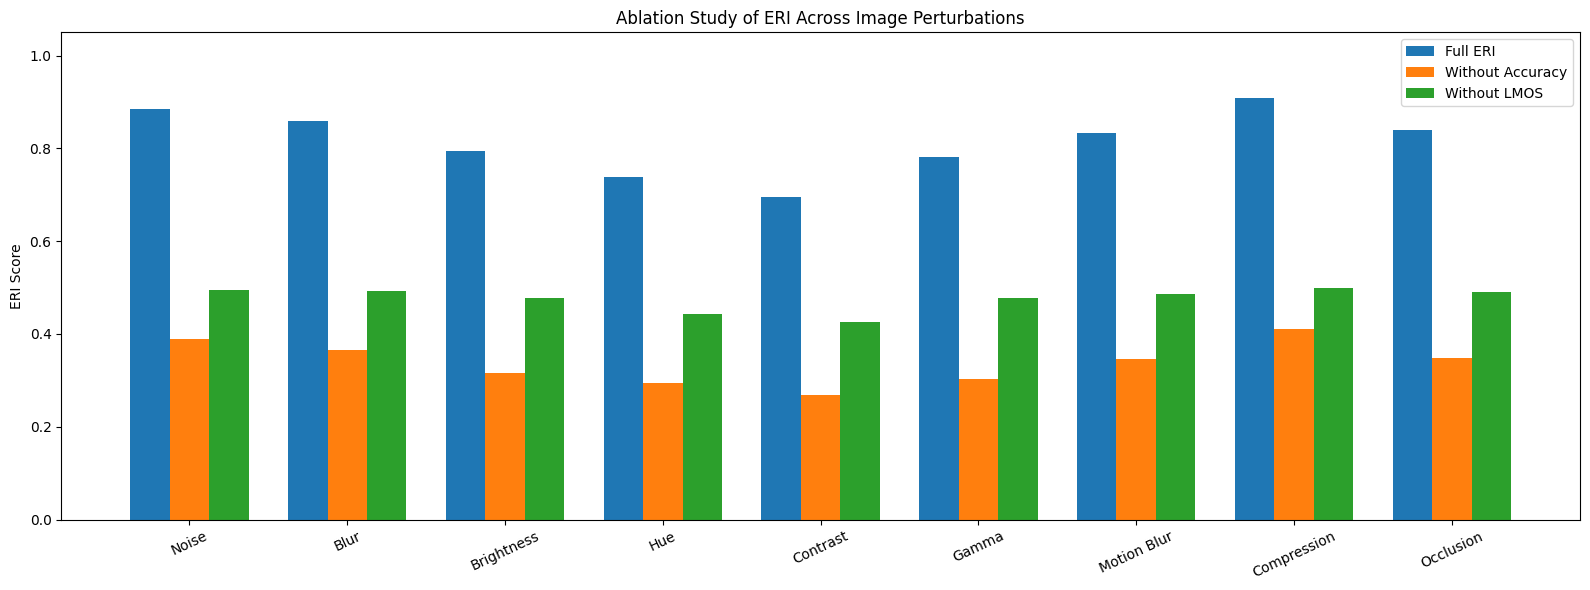

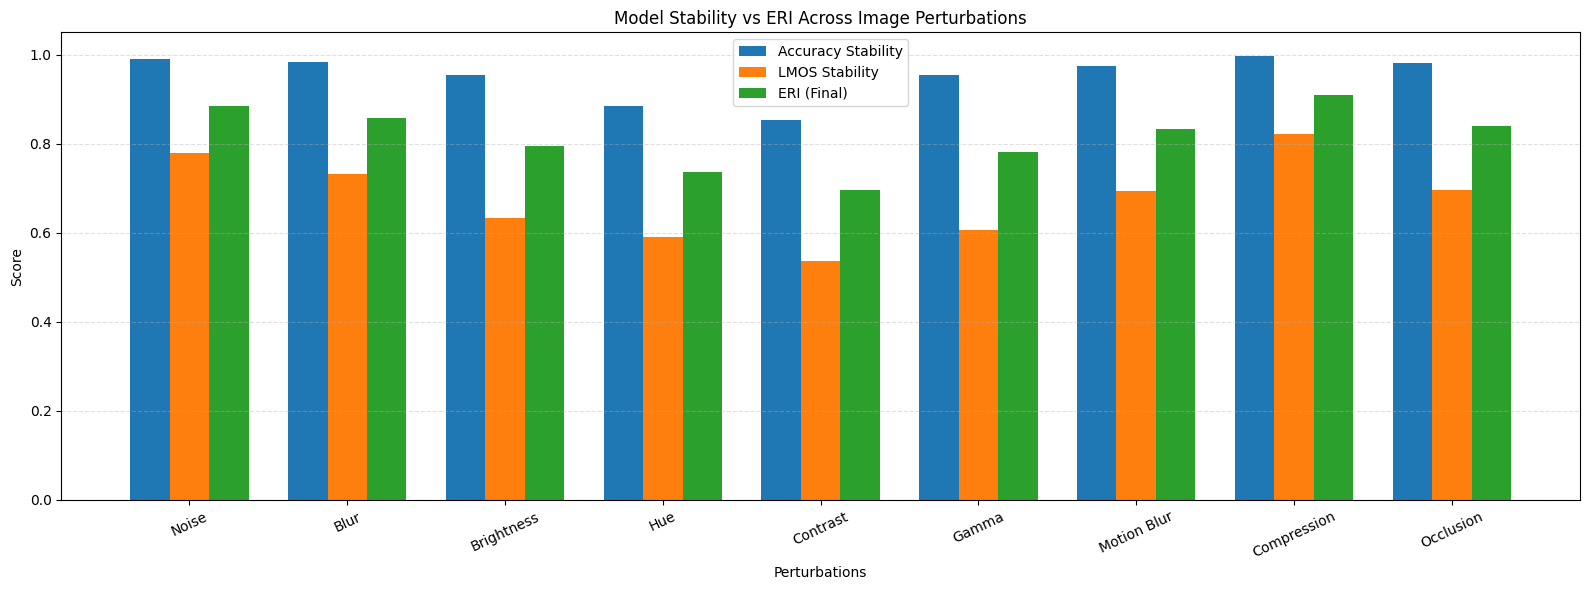

Saved: eri_components_bar.png


In [20]:
import matplotlib.pyplot as plt

# ====================================================
# PERTURBATIONS
# ====================================================

perturbations = [
    "Noise", "Blur", "Brightness", "Hue",
    "Contrast", "Gamma", "Motion Blur",
    "Compression", "Occlusion"
]

# ====================================================
# YOUR VALUES (already computed in your code)
# ====================================================

acc_stab = [
    accuracy_stability_noise,
    accuracy_stability_blur,
    accuracy_stability_brightness,
    accuracy_stability_hue,
    accuracy_stability_contrast,
    accuracy_stability_gamma,
    accuracy_stability_motion_blur,
    accuracy_stability_compression,
    accuracy_stability_occlusion
]

lmos_stab = [
    overlap_pred_stability_noise,
    overlap_pred_stability_blur,
    overlap_pred_stability_brightness,
    overlap_pred_stability_hue,
    overlap_pred_stability_contrast,
    overlap_pred_stability_gamma,
    overlap_pred_stability_motion_blur,
    overlap_pred_stability_compression,
    overlap_pred_stability_occlusion
]

# ====================================================
# ERI COMPUTATION
# ====================================================

eri_full = [(a + l) / 2 for a, l in zip(acc_stab, lmos_stab)]
eri_no_acc = [l / 2 for l in lmos_stab]
eri_no_lmos = [a / 2 for a in acc_stab]

# ====================================================
# PRINT TABLE (IMPORTANT FOR PAPER)
# ====================================================

# ====================================================
# PRINT TABLE (IMPORTANT FOR PAPER)
# ====================================================

df = pd.DataFrame({
    "Perturbation": perturbations,
    "Accuracy_Stability": acc_stab,
    "LMOS_Stability": lmos_stab,
    "ERI_Full": eri_full,
    "ERI_No_Accuracy": eri_no_acc,
    "ERI_No_LMOS": eri_no_lmos
})

# ====================================================
# MEAN VALUES (ADDED)
# ====================================================

mean_accuracy = np.mean(acc_stab)
mean_lmos = np.mean(lmos_stab)
mean_eri = np.mean(eri_full)

print("\n================ ERI ABLATION STUDY TABLE ================\n")
print(df.to_string(index=False))

print("\n================ SUMMARY ================\n")
print(f"Mean Accuracy Stability : {mean_accuracy:.4f}")
print(f"Mean LMOS Stability     : {mean_lmos:.4f}")
print(f"Mean ERI (Full)         : {mean_eri:.4f}")
print(f"Mean ERI (No Accuracy)   : {np.mean(eri_no_acc):.4f}")
print(f"Mean ERI (No LMOS)       : {np.mean(eri_no_lmos):.4f}")
# ====================================================
# PLOT (PUBLICATION STYLE)
# ====================================================

x = np.arange(len(perturbations))
width = 0.25

plt.figure(figsize=(16,6))

bars1 = plt.bar(x - width, eri_full, width, label="Full ERI")
bars2 = plt.bar(x, eri_no_acc, width, label="Without Accuracy")
bars3 = plt.bar(x + width, eri_no_lmos, width, label="Without LMOS")

plt.xticks(x, perturbations, rotation=25)
plt.ylabel("ERI Score")
plt.title("Ablation Study of ERI Across Image Perturbations")
plt.ylim(0, 1.05)
plt.legend()

plt.tight_layout()
plt.savefig("eri_ablation_study_per_perturbation.png", dpi=300, bbox_inches='tight')
plt.show()



# ====================================================
# SECOND FIGURE: BAR CHART (BETTER FOR PAPER)
# ====================================================

plt.figure(figsize=(16,6))

x = np.arange(len(perturbations))
width = 0.25

plt.bar(x - width, acc_stab, width, label="Accuracy Stability")
plt.bar(x, lmos_stab, width, label="LMOS Stability")
plt.bar(x + width, eri_full, width, label="ERI (Final)")

plt.xticks(x, perturbations, rotation=25)
plt.ylabel("Score")
plt.xlabel("Perturbations")
plt.title("Model Stability vs ERI Across Image Perturbations")

plt.ylim(0, 1.05)

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()

plt.savefig(
    "eri_components_bar.png",
    dpi=600,
    bbox_inches='tight'
)

plt.show()

print("Saved: eri_components_bar.png")